In [16]:
import pandas as pd

toxic_df = pd.read_csv( 
    r"C:\Users\sarik\Desktop\Spam-Toxic-Detection\data\toxic_comments.csv",
    encoding="latin-1"
)

toxic_df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [18]:
print(toxic_df.shape)
print(toxic_df.columns)
print(toxic_df.info())

(159571, 8)
Index(['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 9.7 MB
None


In [19]:
toxic_df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [20]:
toxic_df.columns

Index(['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate'],
      dtype='str')

In [21]:
print(toxic_df.shape)
print(toxic_df.columns)

(159571, 8)
Index(['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate'],
      dtype='str')


In [22]:
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print(labels)

['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [23]:
toxic_df[labels].sum().sort_values(ascending=False)

toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64

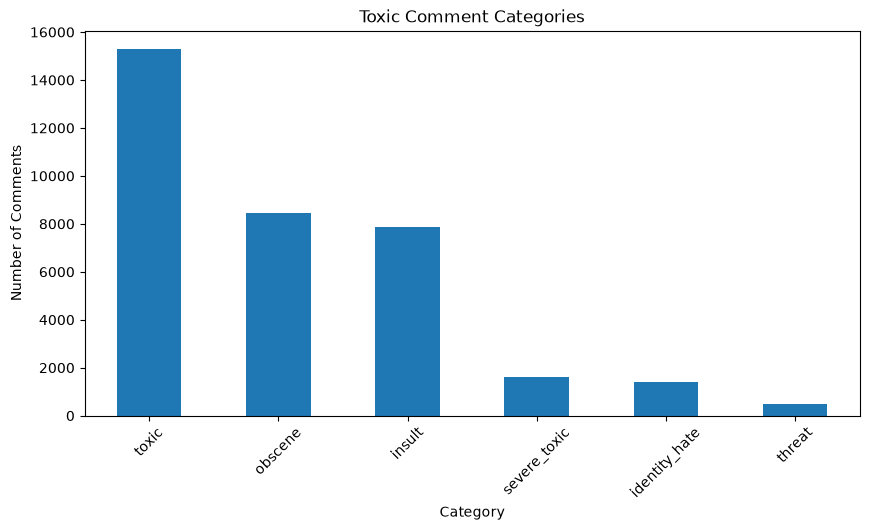

In [24]:
import matplotlib.pyplot as plt

toxic_df[labels].sum().sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Toxic Comment Categories")
plt.xlabel("Category")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.show()

In [25]:
toxic_df.isnull().sum()

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [26]:
toxic_df = toxic_df.dropna(subset=["comment_text"])

In [27]:
print("Duplicates:", toxic_df["comment_text"].duplicated().sum())

Duplicates: 0


In [28]:
toxic_df = toxic_df.drop_duplicates(
    subset=["comment_text"]
)

In [29]:
toxic_df["toxic_label"] = toxic_df[labels].max(axis=1)

In [30]:
toxic_df["toxic_label"].value_counts()

toxic_label
0    143346
1     16225
Name: count, dtype: int64

In [31]:
toxic_df[
    toxic_df["toxic_label"] == 0
]["comment_text"].head(10)

0     Explanation\nWhy the edits made under my usern...
1     D'aww! He matches this background colour I'm s...
2     Hey man, I'm really not trying to edit war. It...
3     "\nMore\nI can't make any real suggestions on ...
4     You, sir, are my hero. Any chance you remember...
5     "\n\nCongratulations from me as well, use the ...
7     Your vandalism to the Matt Shirvington article...
8     Sorry if the word 'nonsense' was offensive to ...
9     alignment on this subject and which are contra...
10    "\nFair use rationale for Image:Wonju.jpg\n\nT...
Name: comment_text, dtype: str

In [32]:
toxic_df[
    toxic_df["toxic_label"] == 1
]["comment_text"].head(10)

6          COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK
12    Hey... what is it..\n@ | talk .\nWhat is it......
16    Bye! \n\nDon't look, come or think of comming ...
42    You are gay or antisemmitian? \n\nArchangel WH...
43             FUCK YOUR FILTHY MOTHER IN THE ASS, DRY!
44    I'm Sorry \n\nI'm sorry I screwed around with ...
51    GET FUCKED UP. GET FUCKEEED UP.  GOT A DRINK T...
55    Stupid peace of shit stop deleting my stuff as...
56    =Tony Sidaway is obviously a fistfuckee. He lo...
58    My Band Page's deletion. You thought I was gon...
Name: comment_text, dtype: str

In [35]:
def clean_text(text):
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    
    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]
    
    return " ".join(words)

In [36]:
import re
import nltk

from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(
    stopwords.words("english")
)


def clean_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+|https\S+",
        "",
        text
    )

    # Remove special characters
    text = re.sub(
        r"[^a-zA-Z\s]",
        "",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    # Remove stopwords
    words = text.split()

    words = [
        word
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sarik\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [37]:
toxic_df["clean_text"] = toxic_df[
    "comment_text"
].apply(clean_text)

In [38]:
toxic_df[
    ["comment_text", "clean_text"]
].head()

,comment_text,clean_text
0,Explanation\nWhy the edits made under my usern...,explanation edits made username hardcore metal...
1,D'aww! He matches this background colour I'm s...,daww matches background colour im seemingly st...
2,"Hey man, I'm really not trying to edit war. It...",hey man im really trying edit war guy constant...
3,"""\nMore\nI can't make any real suggestions on ...",cant make real suggestions improvement wondere...
4,"You, sir, are my hero. Any chance you remember...",sir hero chance remember page thats


In [39]:
X = toxic_df["clean_text"]

y = toxic_df["toxic_label"]

In [51]:
print(X.shape)
print(y.value_counts())

(159571,)
toxic_label
0    143346
1     16225
Name: count, dtype: int64


In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer

toxic_tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

In [54]:
X_train_tfidf = toxic_tfidf.fit_transform(
    X_train
)

In [55]:
X_test_tfidf = toxic_tfidf.transform(
    X_test
)

In [56]:
print("Training:", X_train_tfidf.shape)
print("Testing:", X_test_tfidf.shape)

Training: (127656, 10000)
Testing: (31915, 10000)


In [57]:
from sklearn.svm import LinearSVC

toxic_model = LinearSVC()

toxic_model.fit(
    X_train_tfidf,
    y_train
)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [58]:
toxic_pred = toxic_model.predict(
    X_test_tfidf
)

In [59]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        toxic_pred,
        target_names=[
            "Normal",
            "Toxic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.97      0.99      0.98     28670
       Toxic       0.87      0.69      0.77      3245

    accuracy                           0.96     31915
   macro avg       0.92      0.84      0.87     31915
weighted avg       0.96      0.96      0.96     31915



In [60]:
from sklearn.metrics import accuracy_score

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        toxic_pred
    )
)

Accuracy: 0.9583268055773148


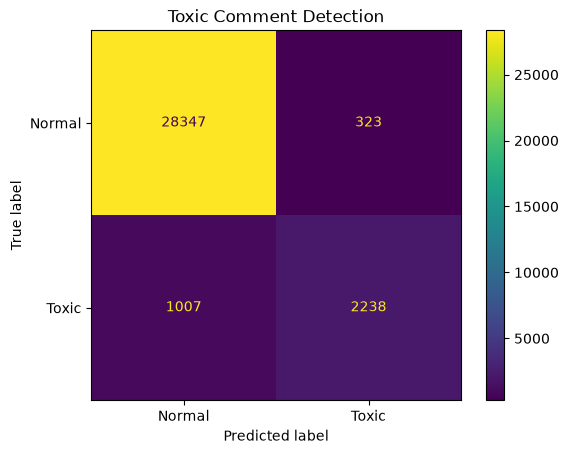

In [61]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    toxic_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal",
        "Toxic"
    ]
)

disp.plot()

plt.title(
    "Toxic Comment Detection"
)

plt.show()

In [62]:
test_comments = [
    "Thank you for sharing this information.",
    "You are a stupid idiot.",
    "I really appreciate your help.",
    "Shut up, nobody wants to hear you.",
    "This is a useful and informative article."
]

In [63]:
clean_comments = [
    clean_text(comment)
    for comment in test_comments
]

In [64]:
comment_vectors = toxic_tfidf.transform(
    clean_comments
)

In [76]:
predictions = toxic_model.predict(
    comment_vectors
)

In [77]:
for comment, prediction in zip(
    test_comments,
    predictions
):

    result = (
        "TOXIC"
        if prediction == 1
        else "NORMAL"
    )

    print("Comment:", comment)
    print("Prediction:", result)
    print("-" * 60)

Comment: Thank you for sharing this information.
Prediction: NORMAL
------------------------------------------------------------
Comment: You are a stupid idiot.
Prediction: TOXIC
------------------------------------------------------------
Comment: I really appreciate your help.
Prediction: NORMAL
------------------------------------------------------------
Comment: Shut up, nobody wants to hear you.
Prediction: TOXIC
------------------------------------------------------------
Comment: This is a useful and informative article.
Prediction: NORMAL
------------------------------------------------------------


In [78]:
import joblib

joblib.dump(
    toxic_tfidf,
    "../models/toxic_tfidf_vectorizer.pkl"
)

joblib.dump(
    toxic_model,
    "../models/toxic_model.pkl"
)

['../models/toxic_model.pkl']